In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency

journeys = pd.read_csv('autonomous_vehicle_journeys.csv')
journeys.head()

,journey_id,journey_date,time_of_day,city,road_segment_id,vehicle_profile_id,weather_code,road_type,distance_km,traffic_level,...,sensor_confidence_pct,sensor_alert_count,unexpected_obstacle,human_intervention,emergency_stop,safety_incident,journey_completed,passenger_rating_1to5,problem_occurred,risk_level
0,AVJ-00001,2026-04-12,Morning peak,Newcastle,SEG-018,VP-08,W07,B road,39.2,High,...,87.6,2,No,No,No,No,Yes,4,No,Low
1,AVJ-00002,2026-06-01,Night,Cardiff,SEG-009,VP-04,W01,Urban street,49.0,Moderate,...,93.5,1,No,No,No,No,Yes,5,No,Low
2,AVJ-00003,2026-02-18,Daytime,Cardiff,SEG-027,VP-08,W05,A road,11.3,Moderate,...,65.9,5,No,Yes,Yes,No,Yes,2,Yes,High
3,AVJ-00004,2026-06-23,Daytime,Cardiff,SEG-021,VP-08,W02,Motorway,15.3,Moderate,...,82.0,2,No,No,No,No,Yes,4,No,Low
4,AVJ-00005,2026-05-08,Daytime,Bristol,SEG-026,VP-04,W02,Motorway,25.1,Moderate,...,88.5,1,No,No,No,No,Yes,5,No,Low


In [28]:
print(journeys.shape)
journeys.info()
print(journeys.isna().sum())
print(journeys['problem_occurred'].value_counts())

(2500, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   journey_id             2500 non-null   object 
 1   journey_date           2500 non-null   object 
 2   time_of_day            2500 non-null   object 
 3   city                   2500 non-null   object 
 4   road_segment_id        2500 non-null   object 
 5   vehicle_profile_id     2500 non-null   object 
 6   weather_code           2500 non-null   object 
 7   road_type              2500 non-null   object 
 8   distance_km            2500 non-null   float64
 9   traffic_level          2500 non-null   object 
 10  road_surface           2500 non-null   object 
 11  visibility_km          2500 non-null   float64
 12  planned_time_min       2500 non-null   int64  
 13  actual_time_min        2500 non-null   int64  
 14  delay_min              2500 non-null   int64 

In [29]:
vehicles = pd.read_csv('vehicle_sensor_profiles.csv')
roads = pd.read_csv('road_environment_factors.csv')
weather = pd.read_csv('weather_risk_factors.csv')
events = pd.read_csv('intervention_events.csv')

In [30]:
data = (journeys
    .merge(vehicles, on='vehicle_profile_id', how='left')
    .merge(roads, on='road_segment_id', how='left', suffixes=('', '_road'))
    .merge(weather, on='weather_code', how='left'))

# Prints the number of entries total (2500)
# Prints how many missing values are of the desired fields
print(data.shape)
print(data[['vehicle_model','junction_complexity','weather']].isna().sum())


(2500, 44)
vehicle_model          0
junction_complexity    0
weather                0
dtype: int64


In [31]:
data['problem_flag'] = (data['problem_occurred'] == 'Yes').astype(int)

weather
Clear          15.7
Strong wind    16.6
Light rain     17.9
Heat alert     22.0
Low sun        26.2
Heavy rain     27.6
Fog            32.5
Snow           47.7
Name: problem_flag, dtype: float64


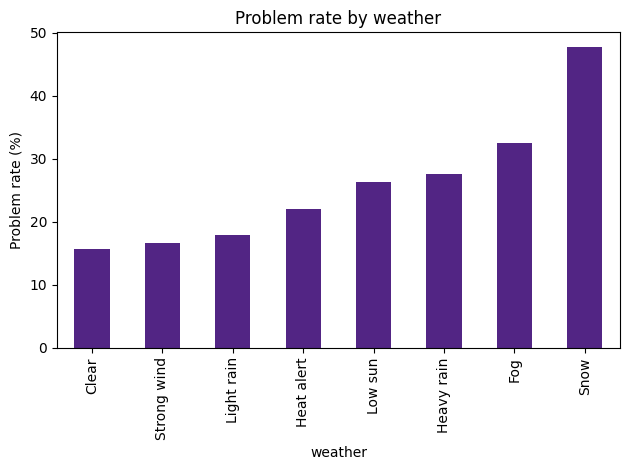

In [32]:
weather_rates = (data.groupby('weather')['problem_flag']
                 .mean().mul(100).sort_values())
print(weather_rates.round(1))
weather_rates.plot(kind='bar', color='#522584')
plt.ylabel('Problem rate (%)')
plt.title('Problem rate by weather')
plt.tight_layout()


In [33]:
pivot = pd.pivot_table(
    data, values='problem_flag',
    index='weather', columns='traffic_level',
    aggfunc='mean') * 100
print(pivot.round(1))


traffic_level  High   Low  Moderate
weather                            
Clear          22.4   8.6      14.6
Fog            34.5  21.9      35.7
Heat alert     26.1  30.8      13.0
Heavy rain     31.0  21.8      28.6
Light rain     18.8  12.4      20.5
Low sun        35.3  29.4      16.1
Snow           40.0  47.4      56.2
Strong wind    22.7  12.8      15.0


Text(0, 0.5, 'Sensor confidence (%)')

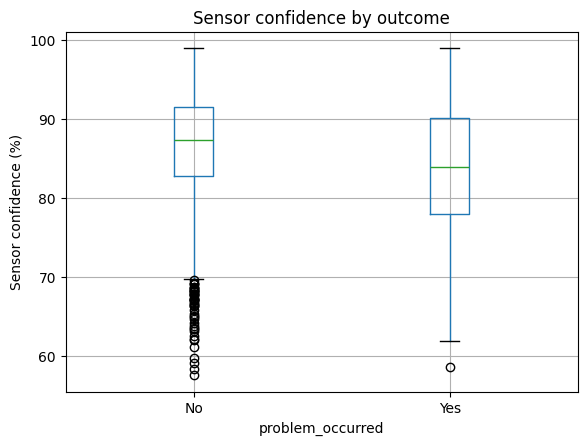

In [34]:
data.boxplot(column='sensor_confidence_pct', by='problem_occurred')
plt.suptitle('')
plt.title('Sensor confidence by outcome')
plt.ylabel('Sensor confidence (%)')


In [47]:
def run_chi2_test(df, feature, target):
    contingency_table = pd.crosstab(df[feature], df[target])
    chi2, p, dof, expected = chi2_contingency(contingency_table)

    # Calculating Cramer's V (Fixed the '- 1' syntax here)
    n = contingency_table.sum().sum()
    min_dim = min(contingency_table.shape) - 1
    cramer_v = np.sqrt(chi2 / (n * min_dim))

    print(f"--- {feature.upper()} ---")
    print(contingency_table)
    print(f"p-value: {p:.4e}")
    print(f"Cramer's V: {cramer_v:.4f}")
    # Added a quick check to satisfy the >= 5 expected frequency assumption
    print(f"Lowest expected frequency: {expected.min():.2f}\n")

In [48]:
# Call the function for all three variables using the merged 'data' dataframe
run_chi2_test(data, 'weather', 'problem_flag')
run_chi2_test(data, 'traffic_level', 'problem_flag')
run_chi2_test(data, 'road_type', 'problem_flag')

--- WEATHER ---
problem_flag     0    1
weather                
Clear         1023  190
Fog            108   52
Heat alert      46   13
Heavy rain     147   56
Light rain     390   85
Low sun        104   37
Snow            45   41
Strong wind    136   27
p-value: 1.8037e-15
Cramer's V: 0.1837
Lowest expected frequency: 11.82

--- TRAFFIC_LEVEL ---
problem_flag     0    1
traffic_level          
High           629  209
Low            528   88
Moderate       842  204
p-value: 2.9382e-06
Cramer's V: 0.1009
Lowest expected frequency: 123.45

--- ROAD_TYPE ---
problem_flag    0    1
road_type             
A road        411   85
B road        401  105
Motorway      444  100
Rural road    380  106
Urban street  363  105
p-value: 1.7593e-01
Cramer's V: 0.0503
Lowest expected frequency: 93.79



In [51]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

features = [
    'time_of_day', 'road_type', 'traffic_level', 'road_surface',
    'visibility_km', 'distance_km', 'sensor_confidence_pct',
    'sensor_alert_count', 'unexpected_obstacle'
]

X = pd.get_dummies(data[features], drop_first=True)
y = data['problem_flag']

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=99, stratify=y
)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model trained and predictions generated.")

Model trained and predictions generated.


Accuracy: 0.944
Precision: 0.7903225806451613
Recall: 0.98
F1: 0.875


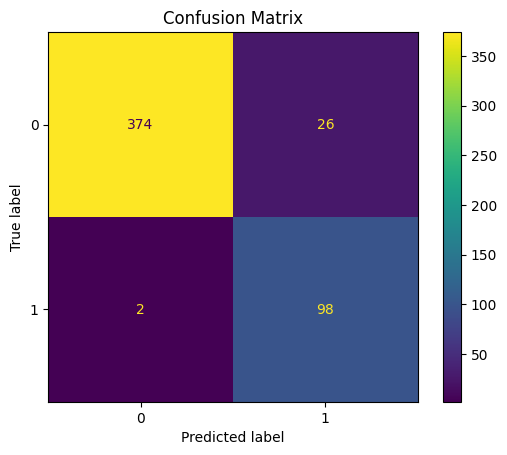

In [54]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Confusion Matrix')
plt.show()

In [55]:
importance = pd.Series(model.coef_[0], index=X.columns)
importance = importance.reindex(importance.abs().sort_values(ascending=False).index)
print(importance.head(12))

sensor_alert_count           5.645066
road_surface_Snow-covered    1.320258
traffic_level_Low           -0.951742
sensor_confidence_pct        0.573989
road_type_Motorway          -0.558664
time_of_day_Morning peak     0.303010
road_surface_Wet            -0.297144
road_type_B road            -0.280862
road_type_Rural road        -0.277040
time_of_day_Late night      -0.272287
time_of_day_Evening peak     0.191059
traffic_level_Moderate      -0.188019
dtype: float64
